<a href="https://colab.research.google.com/github/abdullahamjad20/Artifical-Intelligence-Lab/blob/main/AI%20Lab%202/task3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Q3: depth vs nodes expanded ===
Random moves  Solution depth   Expanded  Generated   Time(s)
           5               5          5         12    0.0001
          10              10         12         24    0.0002
          15              15         34         58    0.0005
          20              20        187        306    0.0028
          25              23       1199       1886    0.0792
Plot saved to depth_vs_nodes.png


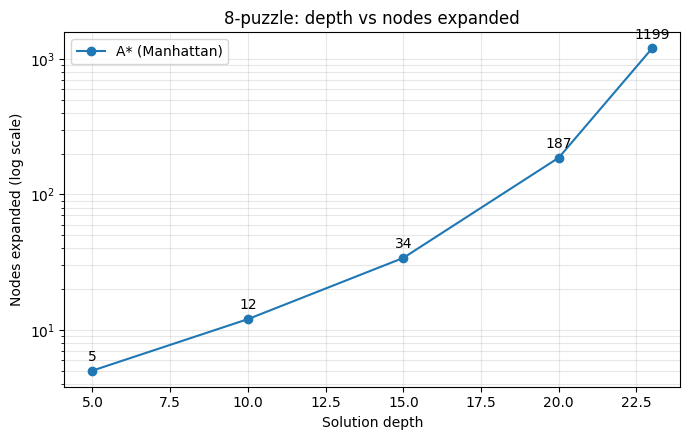

In [8]:
# ===== Question 3 (self-contained) =====
import heapq, random, time
import matplotlib.pyplot as plt

GOAL = (1, 2, 3, 4, 5, 6, 7, 8, 0)
MOVES = {'Up': -3, 'Down': 3, 'Left': -1, 'Right': 1}

def neighbors(state):
    z = state.index(0)
    r, c = divmod(z, 3)
    for name, d in MOVES.items():
        if (name == 'Up' and r == 0) or (name == 'Down' and r == 2) \
           or (name == 'Left' and c == 0) or (name == 'Right' and c == 2):
            continue
        s = list(state)
        s[z], s[z + d] = s[z + d], s[z]
        yield name, tuple(s)

def manhattan(state):
    t = 0
    for i, v in enumerate(state):
        if v:
            g = GOAL.index(v)
            t += abs(i // 3 - g // 3) + abs(i % 3 - g % 3)
    return t

def is_solvable(state):
    t = [x for x in state if x]
    inv = sum(1 for i in range(len(t)) for j in range(i + 1, len(t)) if t[i] > t[j])
    return inv % 2 == 0

def solve(start):
    if not is_solvable(start):
        return None, None
    t0 = time.perf_counter()
    tie = 0
    open_heap = [(manhattan(start), 0, tie, start)]
    parent = {start: None}
    g_cost = {start: 0}
    expanded, generated = 0, 1
    closed = set()
    while open_heap:
        f, g, _, cur = heapq.heappop(open_heap)
        if cur in closed:
            continue
        closed.add(cur)
        if cur == GOAL:
            path = []
            while cur is not None:
                path.append(cur)
                cur = parent[cur]
            path.reverse()
            return path, dict(length=len(path) - 1, expanded=expanded,
                              generated=generated, time=time.perf_counter() - t0)
        expanded += 1
        for _, nxt in neighbors(cur):
            ng = g + 1
            if nxt not in g_cost or ng < g_cost[nxt]:
                g_cost[nxt] = ng
                parent[nxt] = cur
                generated += 1
                tie += 1
                heapq.heappush(open_heap, (ng + manhattan(nxt), ng, tie, nxt))
    return None, None

def random_state(k, seed=None):
    """Apply k random moves to GOAL (never undoing the previous move).
    Always solvable because it is reachable from the goal."""
    rng = random.Random(seed)
    s, last = GOAL, None
    for _ in range(k):
        opts = [t for t in neighbors(s) if t[1] != last]
        _, nxt = rng.choice(opts)
        last, s = s, nxt
    return s

print("=== Q3: depth vs nodes expanded ===")
print(f"{'Random moves':>12} {'Solution depth':>15} {'Expanded':>10} {'Generated':>10} {'Time(s)':>9}")

moves_list, depths, exps = [], [], []
for k in (5, 10, 15, 20, 25):
    s = random_state(k, seed=k)
    path, r = solve(s)
    if r is None:
        print(f"{k:>12}  state {s} unsolvable (should not happen)")
        continue
    print(f"{k:>12} {r['length']:>15} {r['expanded']:>10} {r['generated']:>10} {r['time']:>9.4f}")
    moves_list.append(k)
    depths.append(r['length'])
    exps.append(r['expanded'])

plt.figure(figsize=(7, 4.5))
plt.plot(depths, exps, 'o-', label='A* (Manhattan)')
for d, e in zip(depths, exps):
    plt.annotate(str(e), (d, e), textcoords="offset points", xytext=(0, 7), ha='center')
plt.yscale('log')
plt.xlabel('Solution depth')
plt.ylabel('Nodes expanded (log scale)')
plt.title('8-puzzle: depth vs nodes expanded')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('depth_vs_nodes.png', dpi=120)   # always saves the picture
print("Plot saved to depth_vs_nodes.png")
plt.show()                                    # opens a window (if your system has a display)